In [46]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import swc.aeon.io.api as aeon
from dotmap import DotMap
from swc.aeon.io.video import frames
from swc.aeon.schema.streams import Device

from open_rigs.io.streams import csv, harp_device, raw_video
from open_rigs.io.sync import synchronise_to

from open_rigs_hf_visual.spikeglx import SpikeGLXStream, find_streams

In [107]:
root = Path(r"C:/Users/Saleem Lab/source/repos/hf-visual/temp_data/sub-M26031/ses-20261008_1_date-2026-10-08T15-12-29")

experiment = DotMap(
    [
        Device("Arduino", csv(columns=("encoder_count", "lick_count_left", "lick_count_right", "last_sync_pulse_time", "photodiode", "current_ms"))),
        Device("ArduinoPhotodiode", csv(columns=("photodiode", "sync_val"))),
        Device("Texture", csv(columns=("texture"))),
        Device("VideoData", raw_video()),
    ]
)

In [108]:
arduino_data = aeon.load(root, experiment.Arduino)
arduino_data.head()
arduino_data_photodiode = aeon.load(root, experiment.ArduinoPhotodiode)
texture_data = aeon.load(root, experiment.Texture)

start = aeon.to_datetime(60.0)
end = aeon.to_datetime(70.0)
plt.figure()
plt.plot(arduino_data_photodiode.photodiode[start:end])

ValueError: Duplicate names are not allowed.

## Electrophysiology (SpikeGLX)

The Neuropixels recording for this session was acquired with SpikeGLX and lives in its own run folder,
`M26031_20261008_1_g2` (run name `M26031_20261008_1`, gate `g2`). SpikeGLX writes one flat `int16` binary file per
stream, interleaved by channel, with a `.meta` text file describing it:

- `*_t0.nidq.bin` / `.meta`: the NI-DAQ stream (here 8 analog inputs `XA0..XA7` plus one digital word `XD0`, at 10593.2 Hz).
  `XA0` carries the sync pulses from the rig Arduino and `XD0` bit 3 the 1 Hz SpikeGLX sync square wave.
- `*_imec0/*_t0.imec0.ap.bin`: the probe action-potential band (384 AP channels plus the `SY0` sync channel, at 30 kHz).

`SpikeGLXStream` memory-maps a stream, so the 37 GB probe file can be sliced by time without loading it. `read()` returns
a DataFrame indexed by aeon timestamps counted from the start of that stream, like `aeon.load` does for the other devices.
The ephys clocks are **not** aligned to the Arduino clock here; when needed, that is done with
`open_rigs.io.sync.synchronise_to` using the shared sync pulses (`nidq.rising_edges("XA0")` against
`arduino_data.last_sync_pulse_time`).

> The `imec0.ap.meta` file is missing from this copy of the run folder, so the probe stream geometry is given explicitly:
> 385 channels at 30 kHz, which divides the file size exactly and matches the NI-DAQ duration. Copy the `.meta` file from
> the acquisition PC to get the exact sample rate, channel map and gains; without it the AP values stay in raw ADC units.

In [49]:
ephys_root = root.parents[1] / "M26031_20261008_1_g2"
streams = find_streams(ephys_root)

nidq = SpikeGLXStream(streams["nidq"])
imec = SpikeGLXStream(streams["imec0.ap"], n_channels=385, sample_rate=30000.0)

for name, stream in (("nidq", nidq), ("imec0.ap", imec)):
    print(f"{name}: {stream.n_channels} channels at {stream.sample_rate:g} Hz, {stream.duration:.1f} s")
print("nidq channels:", nidq.channels)

nidq: 9 channels at 10593.2 Hz, 1634.4 s
imec0.ap: 385 channels at 30000 Hz, 1634.4 s
nidq channels: ['XA0', 'XA1', 'XA2', 'XA3', 'XA4', 'XA5', 'XA6', 'XA7', 'XD0']


The Arduino emits a sync pulse at random intervals (1.5 to 4 s) and logs the time of the latest one in
`last_sync_pulse_time` (Arduino milliseconds). The same pulse is recorded by SpikeGLX on NI-DAQ channel `XA0`.
Each clock sees the same sequence of random intervals, so the two pulse trains can be matched by that pattern even
though the recordings started at different times and neither clock is known in terms of the other.

558 pulses logged by the Arduino, 604 pulses seen on XA0
                                     encoder_count  lick_count_left  \
time                                                                  
1904-01-01 00:00:08.005386244+00:00              0                0   
1904-01-01 00:00:08.015390118+00:00              0                0   
1904-01-01 00:00:08.025393991+00:00              0                0   
1904-01-01 00:00:08.035397864+00:00              0                0   
1904-01-01 00:00:08.045401737+00:00              0                0   

                                     lick_count_right  last_sync_pulse_time  \
time                                                                          
1904-01-01 00:00:08.005386244+00:00                 0                   499   
1904-01-01 00:00:08.015390118+00:00                 0                   499   
1904-01-01 00:00:08.025393991+00:00                 0                   499   
1904-01-01 00:00:08.035397864+00:00               

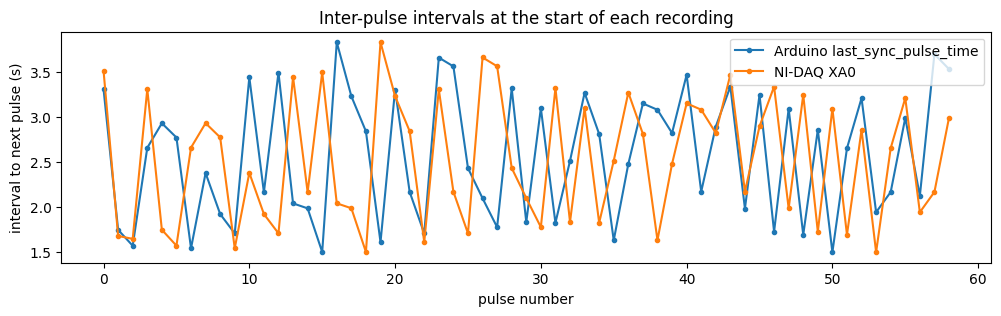

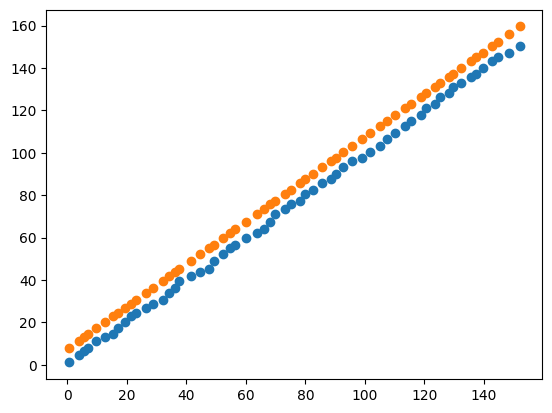

In [88]:
# Pulse times on each clock, in seconds from the start of that clock
arduino_pulses = np.unique(arduino_data.last_sync_pulse_time.to_numpy()) / 1000.0
nidq_pulses = np.asarray(aeon.to_seconds(nidq.rising_edges("XA0")))
print(f"{len(arduino_pulses)} pulses logged by the Arduino, {len(nidq_pulses)} pulses seen on XA0")

# The interval sequences carry the same random pattern, offset by the pulses NI-DAQ saw before the Arduino log began
plt.figure(figsize=(12, 3))
plt.plot(np.diff(arduino_pulses[:60]), ".-", label="Arduino last_sync_pulse_time")
plt.plot(np.diff(nidq_pulses[:60]), ".-", label="NI-DAQ XA0")
plt.xlabel("pulse number")
plt.ylabel("interval to next pulse (s)")
plt.legend()
plt.title("Inter-pulse intervals at the start of each recording")

# In this case it appears that the Arduino started logging after the NI-DAQ had already seen 3 pulses, so we can align the two clocks by ignoring the first 3 pulses on the NI-DAQ side
plt.figure()
plt.scatter(arduino_pulses[:60], nidq_pulses[:60])
plt.scatter(arduino_pulses[:60], nidq_pulses[3:63])

arduino_data_synced = synchronise_to(arduino_data, arduino_pulses[:500], nidq_pulses[3:503])
print(arduino_data_synced.head())

                                     XA0  XA1  XA2  XA3  XA4  XA5  XA6  XA7  \
time                                                                          
1904-01-01 00:00:20+00:00             -6  660  674  677  449  722    2    0   
1904-01-01 00:00:20.000094400+00:00   53  657  672  676  445  722    2    2   
1904-01-01 00:00:20.000188800+00:00   60  700  673  675  444  720    1    2   
1904-01-01 00:00:20.000283201+00:00   48  651  674  676  444  721    4    1   
1904-01-01 00:00:20.000377601+00:00   18  636  665  675  442  719    2    1   

                                     XD0  
time                                      
1904-01-01 00:00:20+00:00              8  
1904-01-01 00:00:20.000094400+00:00    8  
1904-01-01 00:00:20.000188800+00:00    8  
1904-01-01 00:00:20.000283201+00:00    8  
1904-01-01 00:00:20.000377601+00:00    8  


Text(0.5, 1.0, 'Synchronisation Check')

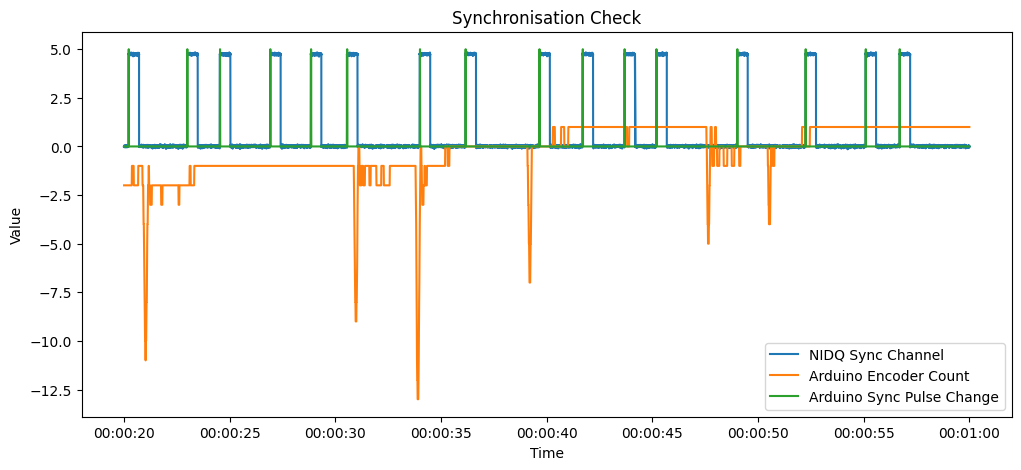

In [104]:
# Sanity check for synchronisation
start = 20
end = 60
nidq_window = nidq.read(start=start, end=end)
seconds = aeon.to_seconds(nidq_window.index)
volts = nidq_window["XA0"] * nidq.volts_per_bit()

print(nidq_window.head())

plt.figure(figsize=(12, 5))
plt.plot(volts, label="NIDQ Sync Channel")
plt.plot(arduino_data_synced.encoder_count[aeon.to_datetime(start):aeon.to_datetime(end)], label="Arduino Encoder Count")
plt.plot(arduino_data_synced.last_sync_pulse_time[aeon.to_datetime(start):aeon.to_datetime(end)].diff().gt(0) * 5.0, label="Arduino Sync Pulse Change")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.title("Synchronisation Check")

### Probe channels

`active_range` scans one channel for the span over which it actually changes value. In this session the probe stream
goes flat (every channel reads zero) about 793 s into the 1634 s recording, so only the first ~13 minutes contain data.
Scanning touches the whole file and takes around 20 s.

In [25]:
active_start, active_end = imec.active_range("AP0")
print(f"probe data present from {active_start:.1f} s to {active_end:.1f} s of {imec.duration:.1f} s")

probe data present from 0.0 s to 793.6 s of 1634.4 s


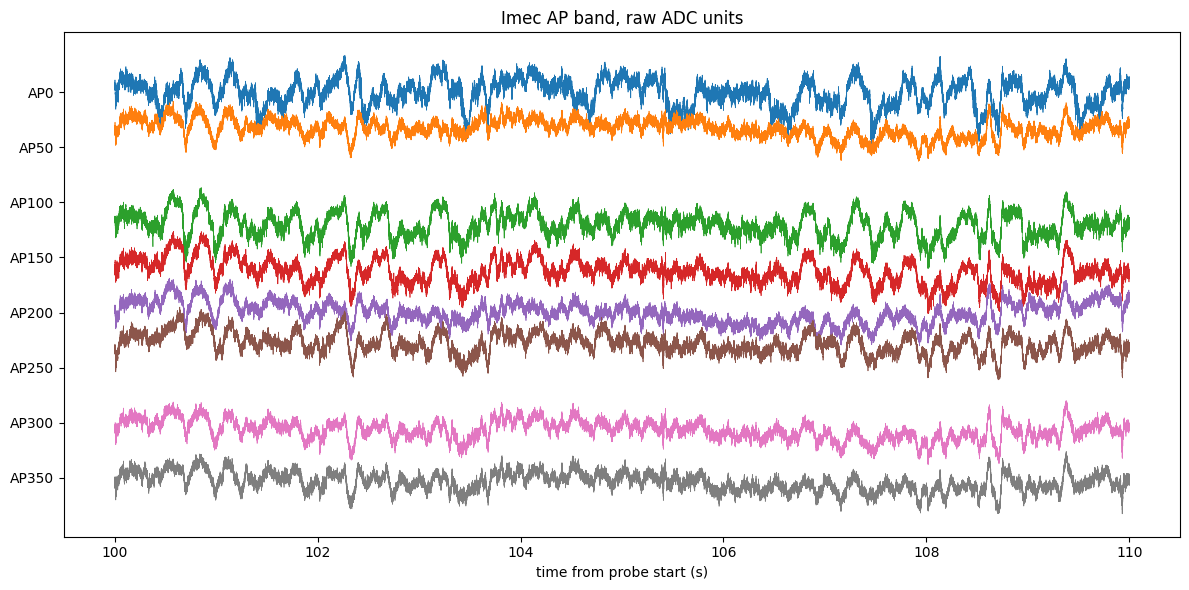

In [26]:
# A short window of a few AP channels, stacked with an offset so the traces do not overlap
channels = ["AP0", "AP50", "AP100", "AP150", "AP200", "AP250", "AP300", "AP350"]
ap_window = imec.read(start=100, end=110, channels=channels)
seconds = aeon.to_seconds(ap_window.index)
offset = 4 * ap_window.std().max()

plt.figure(figsize=(12, 6))
for i, channel in enumerate(channels):
    plt.plot(seconds, ap_window[channel] - i * offset, lw=0.5, label=channel)
plt.yticks(-np.arange(len(channels)) * offset, channels)
plt.xlabel("time from probe start (s)")
plt.title("Imec AP band, raw ADC units")
plt.tight_layout()